# Аналитика над хранилищем hits

Три слоя хранилища:
- `raw.hits` — сырые TSV-файлы в S3 (Garage), сжатые zstd; ClickHouse читает и разбирает их при каждом запросе;
- `hits` — таблица MergeTree: типы, сортировка сайт → пользователь → время, кодеки по колонкам;
- `gold.*` — витрины с заранее посчитанными агрегатами.

In [1]:
import uuid

import clickhouse_connect
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

ch = clickhouse_connect.get_client(host="clickhouse")

LAYER_COLORS = {"raw": "#2a78d6", "hits": "#eb6834", "gold": "#1baf7a"}
BAR = "#2a78d6"
INK, MUTED, SURFACE = "#0b0b0b", "#898781", "#fcfcfb"

plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})


def q(sql, **parameters):
    return ch.query_df(sql, parameters=parameters)


def scalar(sql, **parameters):
    return ch.query(sql, parameters=parameters).result_rows[0][0]


NUMBER = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
SECONDS = FuncFormatter(lambda v, _: f"{v:g}")


def bars(ax, labels, values, color=BAR, horizontal=False, fmt="{:,.0f}"):
    (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(NUMBER)
    if horizontal:
        ax.barh(labels, values, color=color, height=0.6)
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        for y, v in enumerate(values):
            ax.annotate(fmt.format(v).replace(",", " "), (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
    else:
        ax.bar(labels, values, color=color, width=0.7)
        ax.grid(axis="x", visible=False)

## 1. Размер данных по слоям

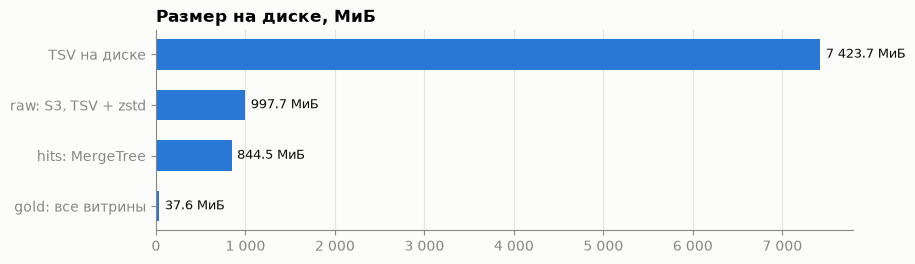

,слой,bytes,MiB,"доля от TSV, %"
0,TSV на диске,7784351125,7423.7,100.00
1,"raw: S3, TSV + zstd",1046187580,997.7,13.44
2,hits: MergeTree,885500403,844.5,11.38
3,gold: все витрины,39402069,37.6,0.51


In [2]:
sizes = pd.DataFrame([
    ("TSV на диске", 7784351125),
    ("raw: S3, TSV + zstd", scalar("SELECT sum(_size) FROM s3(garage, filename='raw/*/hits.tsv.zst', format='One')")),
    ("hits: MergeTree", scalar("SELECT sum(bytes_on_disk) FROM system.parts WHERE database = 'default' AND table = 'hits' AND active")),
    ("gold: все витрины", scalar("SELECT sum(bytes_on_disk) FROM system.parts WHERE database = 'gold' AND active")),
], columns=["слой", "bytes"])
sizes["MiB"] = (sizes["bytes"] / 2**20).round(1)
sizes["доля от TSV, %"] = (sizes["bytes"] / sizes["bytes"].iloc[0] * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 2.6))
bars(ax, sizes["слой"], sizes["MiB"], horizontal=True, fmt="{:,.1f} МиБ")
ax.set_title("Размер на диске, МиБ")
plt.show()
sizes

In [3]:
q('''
SELECT concat(database, '.', table) AS table_name,
       sum(rows) AS total_rows,
       round(sum(bytes_on_disk) / 1048576, 1) AS mib
FROM system.parts
WHERE active AND (database = 'gold' OR (database = 'default' AND table = 'hits'))
GROUP BY table_name
ORDER BY mib DESC
''')

,table_name,total_rows,mib
0,default.hits,8873898,844.5
1,gold.sources_daily,587404,10.9
2,gold.traffic_hourly,670652,10.7
3,gold.devices_daily,570516,9.1
4,gold.traffic_daily,239802,6.9


## 2. Проверка: `hits` совпадает с сырьём

По каждому дню сравниваются число строк и контрольная сумма всех 133 колонок (`sum(cityHash64(*))`, не зависит от порядка строк).

In [4]:
check = q('''
SELECT toString(date) AS day, count() AS raw_rows, sum(cityHash64(*)) AS raw_fingerprint
FROM raw.hits GROUP BY day ORDER BY day
''').merge(q('''
SELECT toString(EventDate) AS day, count() AS hits_rows, sum(cityHash64(*)) AS hits_fingerprint
FROM hits GROUP BY day ORDER BY day
'''), on="day")
check["совпадает"] = (check["raw_rows"] == check["hits_rows"]) & (check["raw_fingerprint"] == check["hits_fingerprint"])
check

,day,raw_rows,raw_fingerprint,hits_rows,hits_fingerprint,совпадает
0,2014-03-17,1406958,4069732414441114283,1406958,4069732414441114283,True
1,2014-03-18,1383658,18056712130436801376,1383658,18056712130436801376,True
2,2014-03-19,1405797,2646291460008772800,1405797,2646291460008772800,True
3,2014-03-20,1353623,6348599481001071443,1353623,6348599481001071443,True
4,2014-03-21,1245779,18186832381828751558,1245779,18186832381828751558,True
5,2014-03-22,1031592,11433705376281384064,1031592,11433705376281384064,True
6,2014-03-23,1046491,9237225012379672881,1046491,9237225012379672881,True


## 3. Аналитика по витринам

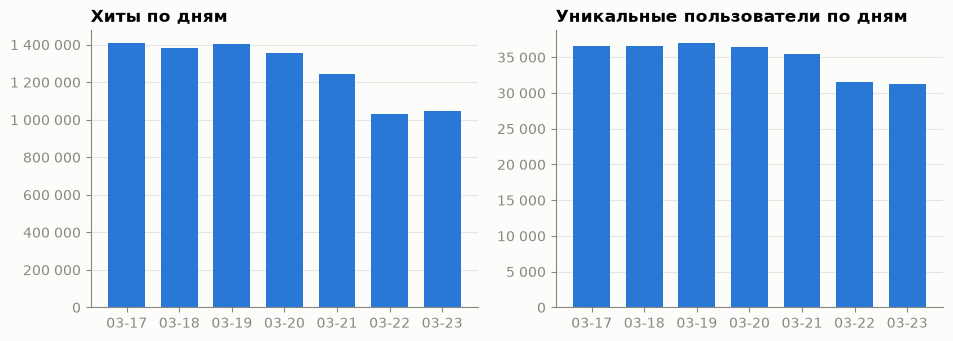

Пользователей за неделю: 120,665; сумма дневных: 244,748


In [5]:
daily = q('''
SELECT toString(EventDate) AS day, sum(hits) AS total_hits, uniqMerge(users) AS total_users
FROM gold.traffic_daily GROUP BY day ORDER BY day
''')

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
bars(left, daily["day"].str[5:], daily["total_hits"])
left.set_title("Хиты по дням")
bars(right, daily["day"].str[5:], daily["total_users"])
right.set_title("Уникальные пользователи по дням")
plt.show()

week_users = scalar("SELECT uniqMerge(users) FROM gold.traffic_daily")
print(f"Пользователей за неделю: {week_users:,}; сумма дневных: {daily['total_users'].sum():,}")

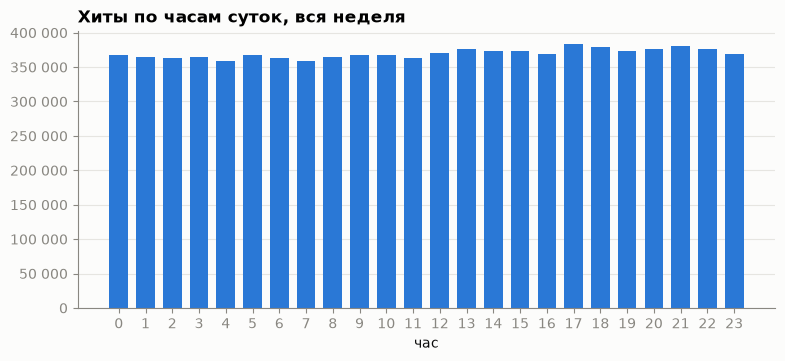

In [6]:
hourly = q("SELECT Hour AS hour, sum(hits) AS total_hits FROM gold.traffic_hourly GROUP BY hour ORDER BY hour")

fig, ax = plt.subplots()
bars(ax, hourly["hour"].astype(str), hourly["total_hits"])
ax.set_title("Хиты по часам суток, вся неделя")
ax.set_xlabel("час")
plt.show()

Профиль по часам почти ровный, хотя у живого трафика обычно есть ночной провал. Похоже, в обезличенном датасете время событий перемешано.

In [7]:
q('''
SELECT CounterID,
       sum(hits) AS total_hits,
       uniqMerge(users) AS total_users,
       round(sum(mobile_hits) / total_hits * 100, 1) AS mobile_pct
FROM gold.traffic_daily
GROUP BY CounterID
ORDER BY total_hits DESC
LIMIT 10
''')

,CounterID,total_hits,total_users,mobile_pct
0,1704509,523264,2867,0.4
1,732797,475698,17464,5.3
2,598875,337212,17992,5.3
3,792887,252197,4883,2.1
4,3807842,196036,3313,7.5
5,25703952,147211,3066,11.4
6,716829,90109,4749,7.4
7,59183,85379,738,36.8
8,33010362,77807,2453,8.5
9,800784,77492,4057,7.0


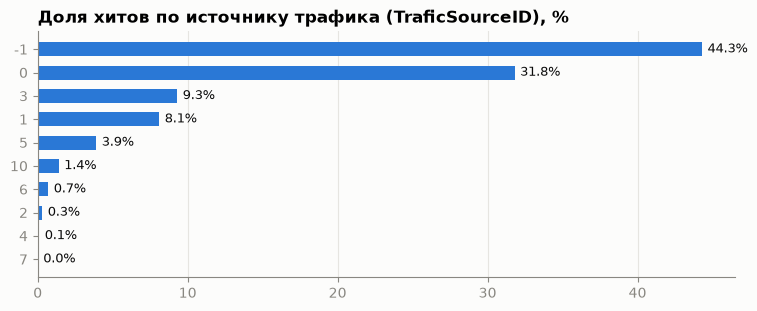

In [8]:
sources = q('''
SELECT toString(TraficSourceID) AS source, sum(hits) AS total_hits
FROM gold.sources_daily GROUP BY source ORDER BY total_hits DESC
''')
sources["share_pct"] = (sources["total_hits"] / sources["total_hits"].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 3.2))
bars(ax, sources["source"], sources["share_pct"], horizontal=True, fmt="{:.1f}%")
ax.set_title("Доля хитов по источнику трафика (TraficSourceID), %")
plt.show()

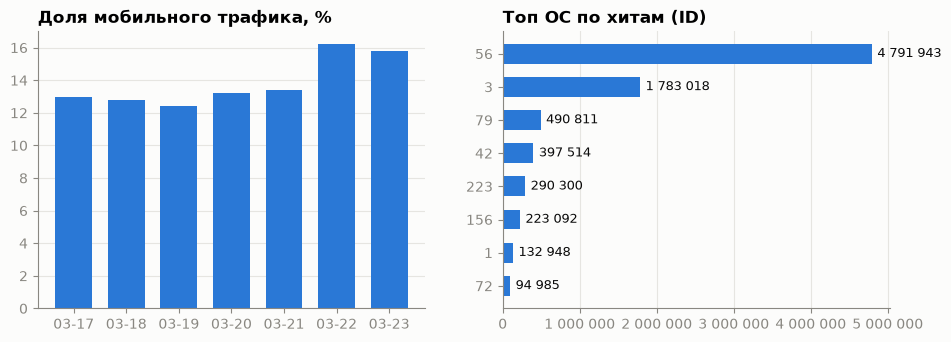

In [9]:
mobile = q('''
SELECT toString(EventDate) AS day, round(sumIf(hits, IsMobile = 1) / sum(hits) * 100, 1) AS mobile_pct
FROM gold.devices_daily GROUP BY day ORDER BY day
''')
os_top = q('''
SELECT toString(OS) AS os, sum(hits) AS total_hits
FROM gold.devices_daily GROUP BY os ORDER BY total_hits DESC LIMIT 8
''')

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
bars(left, mobile["day"].str[5:], mobile["mobile_pct"])
left.set_title("Доля мобильного трафика, %")
bars(right, os_top["os"], os_top["total_hits"], horizontal=True)
right.set_title("Топ ОС по хитам (ID)")
plt.show()

Поисковых фраз в витринах нет — этот вопрос считается по `hits`:

In [10]:
q('''
SELECT SearchPhrase, count() AS total_hits
FROM hits
WHERE SearchPhrase != ''
GROUP BY SearchPhrase
ORDER BY total_hits DESC
LIMIT 10
''')

,SearchPhrase,total_hits
0,ст 12.168.0.1,3567
1,orton,2402
2,игры лица и гым чан дизайн,2166
3,imgsrc,1848
4,брызговик,1659
5,индийский афтозный,1549
6,ооооотводка и,1480
7,выступная мужчин,1247
8,юность,1112
9,пелевиз дсп в москвы о рыжая,1091


## 4. Бенчмарк: один вопрос — три слоя

Каждый запрос выполняется дважды, берётся лучшее время. `rows_read` и `mib_read` — сколько строк и данных (без сжатия) ClickHouse пришлось обработать, по `system.query_log`.

In [11]:
def bench(sql, repeat=2):
    tag = str(uuid.uuid4())
    for _ in range(repeat):
        ch.query(sql, settings={"log_comment": tag})
    ch.command("SYSTEM FLUSH LOGS")
    return q('''
SELECT min(query_duration_ms) / 1000 AS seconds, any(read_rows) AS rows_read, round(any(read_bytes) / 1048576, 1) AS mib_read
FROM system.query_log
WHERE type = 'QueryFinish' AND log_comment = {tag:String}
''', tag=tag).iloc[0].to_dict()


top = scalar("SELECT CounterID FROM gold.traffic_daily GROUP BY CounterID ORDER BY sum(hits) DESC LIMIT 1")

QUERIES = {
    "Хиты и пользователи по дням": {
        "raw": "SELECT date AS day, count() AS total_hits, uniq(UserID) AS total_users FROM raw.hits GROUP BY day ORDER BY day",
        "hits": "SELECT EventDate AS day, count() AS total_hits, uniq(UserID) AS total_users FROM hits GROUP BY day ORDER BY day",
        "gold": "SELECT EventDate AS day, sum(hits) AS total_hits, uniqMerge(users) AS total_users FROM gold.traffic_daily GROUP BY day ORDER BY day",
    },
    "Топ-10 сайтов": {
        "raw": "SELECT CounterID, count() AS total_hits, uniq(UserID) AS total_users FROM raw.hits GROUP BY CounterID ORDER BY total_hits DESC LIMIT 10",
        "hits": "SELECT CounterID, count() AS total_hits, uniq(UserID) AS total_users FROM hits GROUP BY CounterID ORDER BY total_hits DESC LIMIT 10",
        "gold": "SELECT CounterID, sum(hits) AS total_hits, uniqMerge(users) AS total_users FROM gold.traffic_daily GROUP BY CounterID ORDER BY total_hits DESC LIMIT 10",
    },
    f"Хиты по часам, сайт {top}": {
        "raw": f"SELECT toHour(EventTime) AS hour, count() AS total_hits FROM raw.hits WHERE CounterID = {top} GROUP BY hour ORDER BY hour",
        "hits": f"SELECT toHour(EventTime) AS hour, count() AS total_hits FROM hits WHERE CounterID = {top} GROUP BY hour ORDER BY hour",
        "gold": f"SELECT Hour AS hour, sum(hits) AS total_hits FROM gold.traffic_hourly WHERE CounterID = {top} GROUP BY hour ORDER BY hour",
    },
    "Топ-10 поисковых фраз": {
        "raw": "SELECT SearchPhrase, count() AS total_hits FROM raw.hits WHERE SearchPhrase != '' GROUP BY SearchPhrase ORDER BY total_hits DESC LIMIT 10",
        "hits": "SELECT SearchPhrase, count() AS total_hits FROM hits WHERE SearchPhrase != '' GROUP BY SearchPhrase ORDER BY total_hits DESC LIMIT 10",
    },
}

results = pd.DataFrame([
    {"вопрос": question, "слой": layer, **bench(sql)}
    for question, by_layer in QUERIES.items()
    for layer, sql in by_layer.items()
])
results

,вопрос,слой,seconds,rows_read,mib_read
0,Хиты и пользователи по дням,raw,14.831,8873898.0,921.0
1,Хиты и пользователи по дням,hits,0.118,8873898.0,84.6
2,Хиты и пользователи по дням,gold,0.048,239802.0,22.4
3,Топ-10 сайтов,raw,13.728,8873898.0,921.0
4,Топ-10 сайтов,hits,0.164,8873898.0,101.6
5,Топ-10 сайтов,gold,0.077,239802.0,22.9
6,"Хиты по часам, сайт 1704509",raw,14.943,8873898.0,921.0
7,"Хиты по часам, сайт 1704509",hits,0.012,581632.0,4.4
8,"Хиты по часам, сайт 1704509",gold,0.009,57344.0,0.5
9,Топ-10 поисковых фраз,raw,13.851,8873898.0,921.0


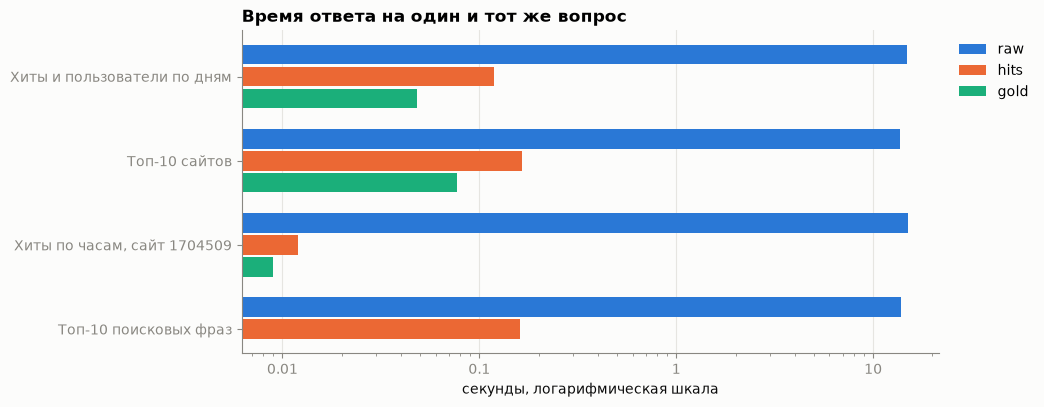

,"raw → hits, раз","hits → gold, раз"
вопрос,,
Хиты и пользователи по дням,126.0,2.0
Топ-10 сайтов,84.0,2.0
"Хиты по часам, сайт 1704509",1245.0,1.0
Топ-10 поисковых фраз,87.0,NaN


In [12]:
seconds = results.pivot(index="вопрос", columns="слой", values="seconds").reindex(QUERIES.keys())[["raw", "hits", "gold"]]
speedup = pd.DataFrame({
    "raw → hits, раз": (seconds["raw"] / seconds["hits"]).round(0),
    "hits → gold, раз": (seconds["hits"] / seconds["gold"]).round(0),
})

fig, ax = plt.subplots(figsize=(9, 4.2))
height = 0.26
for i, layer in enumerate(["raw", "hits", "gold"]):
    ys = [y + (i - 1) * height for y in range(len(seconds))]
    ax.barh(ys, seconds[layer], height=height * 0.9, color=LAYER_COLORS[layer], label=layer)
ax.set_yticks(range(len(seconds)), seconds.index)
ax.invert_yaxis()
ax.set_xscale("log")
ax.xaxis.set_major_formatter(SECONDS)
ax.grid(axis="y", visible=False)
ax.set_xlabel("секунды, логарифмическая шкала")
ax.set_title("Время ответа на один и тот же вопрос")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
speedup

## 5. Как работает индекс

Данные `hits` отсортированы по `CounterID`, поэтому запрос по одному сайту читает только его гранулы (блоки по 8192 строки). Строка `Granules: N/M` — сколько гранул прочитано из скольких.

In [13]:
plan = ch.query(f"EXPLAIN indexes = 1 SELECT toHour(EventTime) AS hour, count() AS total_hits FROM hits WHERE CounterID = {top} GROUP BY hour").result_rows
print("\n".join(row[0] for row in plan))

Output: toHour(EventTime), count()

Aggregating
│  Keys: toHour(EventTime)
│  Aggregates: count()
│  Skip merging: 0
└──ReadFromMergeTree (default.hits)
      Read type: Default
      Parts: 7 | Granules: 71
      Output: EventTime
      Prewhere filter
      Prewhere filter column:  CounterID = 1704509
      Indexes:
        Min-Max
          Condition: true
          Parts: 7/7
          Granules: 1092/1092
        Partition
          Condition: true
          Parts: 7/7
          Granules: 1092/1092
        PrimaryKey
          Keys:
            CounterID
          Condition: (CounterID in [1704509, 1704509])
          Parts: 7/7
          Granules: 71/1092
          Search Algorithm: binary search
        Ranges: 7


## 6. Сэмплирование

`SAMPLE BY intHash32(UserID)` позволяет считать по доле пользователей: `SAMPLE 0.1` — ровно 10% пользователей со всеми их хитами.
Оценка числа пользователей получается близкой к точной. Выигрыш по времени на всей таблице небольшой: ключ сэмплирования стоит вторым после `CounterID`,
поэтому ClickHouse может пропустить мало гранул целиком. Заметнее эффект в запросах по одному сайту.

In [14]:
pd.DataFrame([
    {"запрос": "все данные", "пользователей": scalar("SELECT uniq(UserID) FROM hits"), **bench("SELECT uniq(UserID) FROM hits")},
    {"запрос": "SAMPLE 0.1 × 10", "пользователей": scalar("SELECT uniq(UserID) * 10 FROM hits SAMPLE 0.1"), **bench("SELECT uniq(UserID) * 10 FROM hits SAMPLE 0.1")},
])

,запрос,пользователей,seconds,rows_read,mib_read
0,все данные,120665,0.055,8873898.0,67.7
1,SAMPLE 0.1 × 10,118750,0.049,7334788.0,56.0


## Выводы

- **Размер.** TSV 7.25 ГиБ → сырьё в S3 ~1 ГиБ (zstd) → `hits` ~845 МиБ → все витрины ~38 МиБ.
- **Корректность.** По всем 7 дням число строк и контрольная сумма `hits` совпадают с сырьём.
- **Скорость.** Запрос к сырью занимает ~14–15 с на любой вопрос: ClickHouse каждый раз скачивает, распаковывает и разбирает весь TSV.
  Тот же вопрос к `hits` — от сотых до десятых долей секунды (примерно в 80–1000 раз быстрее): читаются только нужные колонки в бинарном виде.
  Витрины читают в 10–37 раз меньше строк, чем `hits`. На нашем объёме это разница в сотые доли секунды, но с ростом данных она растёт пропорционально.
- **Сортировка.** На размер она почти не влияет, зато запрос по одному сайту читает около 6% гранул (`EXPLAIN` выше) — отсюда самый большой выигрыш в бенчмарке.
- **Уникальные пользователи.** Сумма дневных пользователей примерно вдвое больше реального числа за неделю, поэтому в витринах хранится `uniqState`, а не число.